# Analítica comercial reproducible con Python

**Autor:** Marko Naveda  
**Contexto:** Proyecto académico final del curso de Python for Data Science, especialización Data Science for Business (UPC).

## 1. Presentar al autor y la pregunta

 **Pregunta central:** ¿Cómo evolucionaron las ventas y qué canal y categoría muestran el mejor desempeño entre enero y junio?

Plan de análisis: primero se inspeccionarán los datos originales sin modificarlos. Luego se aplicarán reglas de validación con una función, condicionales, un bucle y continue. Con los registros válidos se calcularán indicadores con NumPy, se construirán columnas, filtros y resúmenes con pandas, y finalmente se comunicarán los resultados mediante gráficos, hallazgos, recomendaciones y una limitación.


# 2. Preparar e inspeccionar los datos

En esta etapa se conservan los 12 registros originales. Solo se inspecciona la estructura del conjunto de datos antes de aplicar cualquier regla de validación.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

datos = {
    "mes": ["Ene","Ene","Feb","Feb","Mar","Mar","Abr","Abr","May","May","Jun","Jun"],
    "canal": ["Web","Tienda","Web","Tienda","Web","Tienda","Web","Tienda","Web","Tienda","Web","Tienda"],
    "categoria": ["Tecnologia","Hogar","Tecnologia","Servicios","Hogar","Tecnologia",
                  "Servicios","Hogar","Tecnologia","Servicios","Hogar","Tecnologia"],
    "ventas": [1250,980,1540,1120,0,1380,1760,1490,1890,1580,2050,1700],
    "costos": [760,640,920,700,0,850,1060,930,1110,990,1220,1080],
    "clientes": [32,27,38,30,0,34,42,37,46,40,50,43],
    "estado": ["Aprobada","Aprobada","Aprobada","Aprobada","Anulada","Aprobada",
               "Aprobada","Observada","Aprobada","Aprobada","Aprobada","Aprobada"]
}

df = pd.DataFrame(datos)

print("Forma del DataFrame:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)

print("\nPrimeras filas:")
display(df.head())

print("\nValores únicos de estado:")
print(df["estado"].unique())

Forma del DataFrame: (12, 7)

Tipos de datos:
mes          object
canal        object
categoria    object
ventas        int64
costos        int64
clientes      int64
estado       object
dtype: object

Primeras filas:


,mes,canal,categoria,ventas,costos,clientes,estado
0,Ene,Web,Tecnologia,1250,760,32,Aprobada
1,Ene,Tienda,Hogar,980,640,27,Aprobada
2,Feb,Web,Tecnologia,1540,920,38,Aprobada
3,Feb,Tienda,Servicios,1120,700,30,Aprobada
4,Mar,Web,Hogar,0,0,0,Anulada



Valores únicos de estado:
['Aprobada' 'Anulada' 'Observada']


Lectura inicial: cada fila representa un registro comercial mensual asociado a un canal y una categoría. La columna `estado` contiene los valores Aprobada, Anulada y Observada, por lo que será utilizada como parte de la validación.

# 3. Validar con control de flujo y una función

Se aplicarán las siguientes reglas:

- estado debe ser Aprobada
- ventas debe ser mayor que 0.
- clientes debe ser mayor que 0

La función propia recibe los valores necesarios y devuelve dos resultados: si el registro es válido y el motivo de exclusión cuando no lo es. Después se recorren las posiciones con `for` y `range(len(df))`, usando `continue` para pasar al siguiente registro cuando una regla no se cumple.

In [3]:
def validar_registro(estado, ventas, clientes):
    if estado != "Aprobada":
        return False, f"Estado no procesable: {estado}"
    if ventas <= 0:
        return False, "Ventas menores o iguales a cero"
    if clientes <= 0:
        return False, "Clientes menores o iguales a cero"
    return True, "Registro válido"


indices_validos = []
exclusiones = []

for posicion in range(len(df)):
    estado = df.loc[posicion, "estado"]
    ventas = df.loc[posicion, "ventas"]
    clientes = df.loc[posicion, "clientes"]

    es_valido, motivo = validar_registro(estado, ventas, clientes)

    if not es_valido:
        exclusiones.append({
            "indice": posicion,
            "mes": df.loc[posicion, "mes"],
            "canal": df.loc[posicion, "canal"],
            "estado": estado,
            "ventas": ventas,
            "clientes": clientes,
            "motivo": motivo
        })
        continue

    indices_validos.append(posicion)

df_valido = df.loc[indices_validos].copy()
df_exclusiones = pd.DataFrame(exclusiones)

print("Índices válidos:", indices_validos)
print("Cantidad de registros válidos:", len(indices_validos))
print("Cantidad de registros excluidos:", len(exclusiones))

print("\nRegistros excluidos y motivo:")
display(df_exclusiones)

print("\nDataFrame válido:")
display(df_valido)

Índices válidos: [0, 1, 2, 3, 5, 6, 8, 9, 10, 11]
Cantidad de registros válidos: 10
Cantidad de registros excluidos: 2

Registros excluidos y motivo:


,indice,mes,canal,estado,ventas,clientes,motivo
0,4,Mar,Web,Anulada,0,0,Estado no procesable: Anulada
1,7,Abr,Tienda,Observada,1490,37,Estado no procesable: Observada



DataFrame válido:


,mes,canal,categoria,ventas,costos,clientes,estado
0,Ene,Web,Tecnologia,1250,760,32,Aprobada
1,Ene,Tienda,Hogar,980,640,27,Aprobada
2,Feb,Web,Tecnologia,1540,920,38,Aprobada
3,Feb,Tienda,Servicios,1120,700,30,Aprobada
5,Mar,Tienda,Tecnologia,1380,850,34,Aprobada
6,Abr,Web,Servicios,1760,1060,42,Aprobada
8,May,Web,Tecnologia,1890,1110,46,Aprobada
9,May,Tienda,Servicios,1580,990,40,Aprobada
10,Jun,Web,Hogar,2050,1220,50,Aprobada
11,Jun,Tienda,Tecnologia,1700,1080,43,Aprobada


In [4]:
# Verificación explícita del resultado esperado
assert len(df_valido) == 10, "La validación debería conservar 10 registros."
assert len(df_exclusiones) == 2, "La validación debería excluir 2 registros."

print("Validación correcta: 10 registros válidos y 2 excluidos.")

Validación correcta: 10 registros válidos y 2 excluidos.


# 4. Calcular indicadores con NumPy

Los arreglos de NumPy se crean únicamente a partir de los registros válidos. De esta manera, los indicadores generales no incluyen registros anulados u observados.

In [5]:
ventas_array = df_valido["ventas"].to_numpy()
costos_array = df_valido["costos"].to_numpy()

utilidad_array = ventas_array - costos_array
ventas_totales = ventas_array.sum()
utilidad_total = utilidad_array.sum()
venta_promedio = ventas_array.mean()

mascara_sobre_promedio = ventas_array > venta_promedio
cantidad_sobre_promedio = mascara_sobre_promedio.sum()

print("Array de ventas:")
print(ventas_array)

print("\nArray de costos:")
print(costos_array)

print("\nUtilidad por registro:")
print(utilidad_array)

print(f"\nVentas totales: S/ {ventas_totales:,.2f}")
print(f"Utilidad total: S/ {utilidad_total:,.2f}")
print(f"Venta promedio: S/ {venta_promedio:,.2f}")
print("Máscara de ventas > promedio:")
print(mascara_sobre_promedio)
print("Cantidad de registros sobre el promedio:", cantidad_sobre_promedio)

Array de ventas:
[1250  980 1540 1120 1380 1760 1890 1580 2050 1700]

Array de costos:
[ 760  640  920  700  850 1060 1110  990 1220 1080]

Utilidad por registro:
[490 340 620 420 530 700 780 590 830 620]

Ventas totales: S/ 15,250.00
Utilidad total: S/ 5,920.00
Venta promedio: S/ 1,525.00
Máscara de ventas > promedio:
[False False  True False False  True  True  True  True  True]
Cantidad de registros sobre el promedio: 6


# 5. Analizar con pandas

Se agregan tres columnas derivadas:

- utilidad: ventas menos costos.
- margen_pct: utilidad como porcentaje de las ventas.
- venta_cliente: ventas divididas entre clientes.

Luego se identifican los registros con ventas superiores al promedio y margen de al menos 35 %, y se construyen resúmenes por canal, categoría y mes.

In [6]:
df_valido["utilidad"] = df_valido["ventas"] - df_valido["costos"]
df_valido["margen_pct"] = df_valido["utilidad"] / df_valido["ventas"] * 100
df_valido["venta_cliente"] = df_valido["ventas"] / df_valido["clientes"]

print("DataFrame válido enriquecido:")
display(df_valido.round({"margen_pct": 2, "venta_cliente": 2}))

filtro_destacados = (
    (df_valido["ventas"] > venta_promedio) &
    (df_valido["margen_pct"] >= 35)
)

registros_destacados = df_valido.loc[
    filtro_destacados,
    ["mes", "canal", "categoria", "ventas", "utilidad", "margen_pct", "venta_cliente"]
]

print("\nRegistros destacados:")
display(registros_destacados.round({"margen_pct": 2, "venta_cliente": 2}))

print("Cantidad de registros destacados:", len(registros_destacados))

DataFrame válido enriquecido:


,mes,canal,categoria,ventas,costos,clientes,estado,utilidad,margen_pct,venta_cliente
0,Ene,Web,Tecnologia,1250,760,32,Aprobada,490,39.20,39.06
1,Ene,Tienda,Hogar,980,640,27,Aprobada,340,34.69,36.30
2,Feb,Web,Tecnologia,1540,920,38,Aprobada,620,40.26,40.53
3,Feb,Tienda,Servicios,1120,700,30,Aprobada,420,37.50,37.33
5,Mar,Tienda,Tecnologia,1380,850,34,Aprobada,530,38.41,40.59
6,Abr,Web,Servicios,1760,1060,42,Aprobada,700,39.77,41.90
8,May,Web,Tecnologia,1890,1110,46,Aprobada,780,41.27,41.09
9,May,Tienda,Servicios,1580,990,40,Aprobada,590,37.34,39.50
10,Jun,Web,Hogar,2050,1220,50,Aprobada,830,40.49,41.00
11,Jun,Tienda,Tecnologia,1700,1080,43,Aprobada,620,36.47,39.53



Registros destacados:


,mes,canal,categoria,ventas,utilidad,margen_pct,venta_cliente
2,Feb,Web,Tecnologia,1540,620,40.26,40.53
6,Abr,Web,Servicios,1760,700,39.77,41.90
8,May,Web,Tecnologia,1890,780,41.27,41.09
9,May,Tienda,Servicios,1580,590,37.34,39.50
10,Jun,Web,Hogar,2050,830,40.49,41.00
11,Jun,Tienda,Tecnologia,1700,620,36.47,39.53


Cantidad de registros destacados: 6


In [7]:
resumen_canal = (
    df_valido.groupby("canal", as_index=False)
    .agg(
        ventas_totales=("ventas", "sum"),
        utilidad_total=("utilidad", "sum"),
        margen_promedio=("margen_pct", "mean"),
        clientes_totales=("clientes", "sum"),
        venta_cliente_promedio=("venta_cliente", "mean")
    )
)

resumen_categoria = (
    df_valido.groupby("categoria", as_index=False)
    .agg(
        ventas_totales=("ventas", "sum"),
        utilidad_total=("utilidad", "sum"),
        margen_promedio=("margen_pct", "mean"),
        clientes_totales=("clientes", "sum")
    )
)

# sort=False conserva el orden de aparición: Ene, Feb, Mar, Abr, May, Jun.
resumen_mes = (
    df_valido.groupby("mes", as_index=False, sort=False)
    .agg(
        ventas_totales=("ventas", "sum"),
        utilidad_total=("utilidad", "sum"),
        clientes_totales=("clientes", "sum")
    )
)

print("Resumen por canal:")
display(resumen_canal.round({"margen_promedio": 2, "venta_cliente_promedio": 2}))

print("\nResumen por categoría:")
display(resumen_categoria.round({"margen_promedio": 2}))

print("\nResumen por mes:")
display(resumen_mes)

Resumen por canal:


,canal,ventas_totales,utilidad_total,margen_promedio,clientes_totales,venta_cliente_promedio
0,Tienda,6760,2500,36.88,174,38.65
1,Web,8490,3420,40.20,208,40.72



Resumen por categoría:


,categoria,ventas_totales,utilidad_total,margen_promedio,clientes_totales
0,Hogar,3030,1170,37.59,77
1,Servicios,4460,1710,38.20,112
2,Tecnologia,7760,3040,39.12,193



Resumen por mes:


,mes,ventas_totales,utilidad_total,clientes_totales
0,Ene,2230,830,59
1,Feb,2660,1040,68
2,Mar,1380,530,34
3,Abr,1760,700,42
4,May,3470,1370,86
5,Jun,3750,1450,93


### Comprobación de coherencia

Se comparan los indicadores generales obtenidos con NumPy contra la suma de los resúmenes de pandas. Esto permite verificar que tablas e indicadores se construyeron con el mismo conjunto de registros válidos.

In [8]:
ventas_desde_canales = resumen_canal["ventas_totales"].sum()
utilidad_desde_canales = resumen_canal["utilidad_total"].sum()

ventas_desde_categorias = resumen_categoria["ventas_totales"].sum()
utilidad_desde_categorias = resumen_categoria["utilidad_total"].sum()

ventas_desde_meses = resumen_mes["ventas_totales"].sum()
utilidad_desde_meses = resumen_mes["utilidad_total"].sum()

print("COMPARACIÓN DE VENTAS")
print(f"NumPy:            S/ {ventas_totales:,.2f}")
print(f"Por canal:        S/ {ventas_desde_canales:,.2f}")
print(f"Por categoría:    S/ {ventas_desde_categorias:,.2f}")
print(f"Por mes:          S/ {ventas_desde_meses:,.2f}")

print("\nCOMPARACIÓN DE UTILIDAD")
print(f"NumPy:            S/ {utilidad_total:,.2f}")
print(f"Por canal:        S/ {utilidad_desde_canales:,.2f}")
print(f"Por categoría:    S/ {utilidad_desde_categorias:,.2f}")
print(f"Por mes:          S/ {utilidad_desde_meses:,.2f}")

assert ventas_totales == ventas_desde_canales == ventas_desde_categorias == ventas_desde_meses
assert utilidad_total == utilidad_desde_canales == utilidad_desde_categorias == utilidad_desde_meses

print("\nLos indicadores generales coinciden con los tres resúmenes.")

COMPARACIÓN DE VENTAS
NumPy:            S/ 15,250.00
Por canal:        S/ 15,250.00
Por categoría:    S/ 15,250.00
Por mes:          S/ 15,250.00

COMPARACIÓN DE UTILIDAD
NumPy:            S/ 5,920.00
Por canal:        S/ 5,920.00
Por categoría:    S/ 5,920.00
Por mes:          S/ 5,920.00

Los indicadores generales coinciden con los tres resúmenes.


# 6. Visualizar los resultados

Se construye una sola figura con tres vistas complementarias, todas obtenidas desde los resúmenes calculados en la sección anterior.

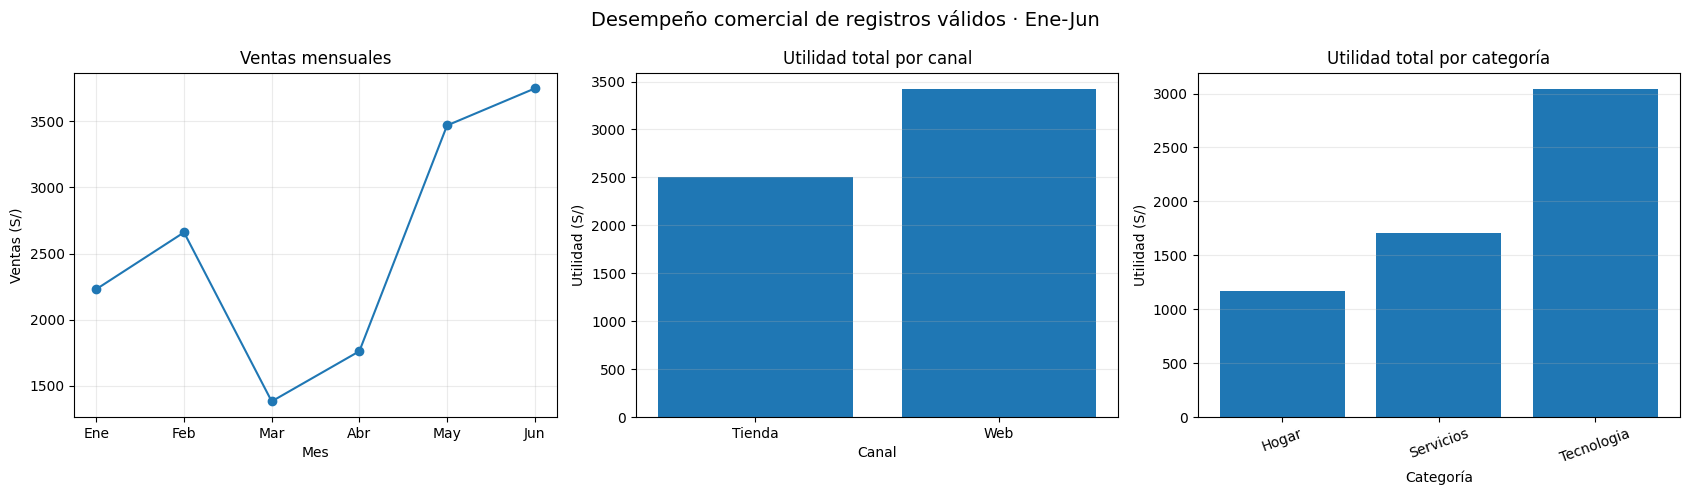

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))

# 1) Ventas mensuales
ax[0].plot(
    resumen_mes["mes"],
    resumen_mes["ventas_totales"],
    marker="o"
)
ax[0].set_title("Ventas mensuales")
ax[0].set_xlabel("Mes")
ax[0].set_ylabel("Ventas (S/)")
ax[0].grid(alpha=0.25)

# 2) Utilidad por canal
ax[1].bar(
    resumen_canal["canal"],
    resumen_canal["utilidad_total"]
)
ax[1].set_title("Utilidad total por canal")
ax[1].set_xlabel("Canal")
ax[1].set_ylabel("Utilidad (S/)")
ax[1].grid(axis="y", alpha=0.25)

# 3) Utilidad por categoría
ax[2].bar(
    resumen_categoria["categoria"],
    resumen_categoria["utilidad_total"]
)
ax[2].set_title("Utilidad total por categoría")
ax[2].set_xlabel("Categoría")
ax[2].set_ylabel("Utilidad (S/)")
ax[2].grid(axis="y", alpha=0.25)
ax[2].tick_params(axis="x", rotation=20)

fig.suptitle("Desempeño comercial de registros válidos · Ene-Jun", fontsize=14)
fig.tight_layout()
plt.show()

# 7. Responder y recomendar

## Hallazgos

1. Evolución mensual.
El `resumen_mes` y el gráfico de línea muestran que las ventas válidas pasan de S/ 2,230 en enero a S/ 2,660 en febrero, caen a S/ 1,380 en marzo y luego se recuperan hasta alcanzar S/ 3,750 en junio, el mayor valor del periodo. La caída de marzo está influida por la exclusión del registro anulado de ese mes.

2. Comparación de canales.  
El `resumen_canal` muestra que Web obtuvo S/ 8,490 en ventas y S/ 3,420 de utilidad, mientras que Tienda alcanzó S/ 6,760 en ventas y S/ 2,500 de utilidad. Por tanto, Web presenta el mejor desempeño agregado entre los dos canales.

3. Comparación de categorías.
Según `resumen_categoria` y el gráfico de utilidad por categoría, Tecnologia lidera con S/ 7,760 en ventas y S/ 3,040 de utilidad. Le siguen Servicios y Hogar, por lo que Tecnologia es la categoría con mayor aporte al desempeño general del periodo.

4. Efecto de la depuración.  
La validación dejó 10 registros válidos y 2 excluidos. El registro de marzo fue excluido por estado Anulada y el de abril por estado Observada. La exclusión de estos registros evita que operaciones no procesables entren en los indicadores; en particular, la observación de abril tenía S/ 1,490 en ventas, por lo que incluirla habría sobreestimado las ventas procesables.

## Recomendaciones

1. Fortalecer el canal Web.  
Conviene priorizar campañas, seguimiento comercial y acciones de conversión en Web, ya que el resumen por canal evidencia la mayor venta y utilidad acumulada. Al mismo tiempo, se debe identificar qué prácticas del canal Web pueden trasladarse a Tienda.

2. Potenciar Tecnologia y revisar meses de menor desempeño.  
Tecnologia es la categoría con mayor utilidad acumulada. Se recomienda mantener su impulso comercial y analizar las causas operativas de los meses con menor venta válida, especialmente marzo y abril, para distinguir entre una caída real de demanda y el efecto de registros excluidos.

## Limitación

El análisis se basa únicamente en 12 registros agregados entre enero y junio, de los cuales 10 son procesables. No se dispone de variables como producto específico, región, vendedor, campaña, fecha diaria o motivo detallado de anulación/observación. Por ello, los resultados permiten comparar desempeño agregado, pero no explicar causalmente por qué ocurren las variaciones.